**Importação de bibliotecas**

In [25]:
historico_alteracoes = []

def exibir_historico():
    print("\n" + "=" * 72)
    print("HISTÓRICO DE ALTERAÇÕES".center(72))
    print("=" * 72)
    for numero, alteracao in enumerate(historico_alteracoes, start=1):
        print(f"{numero:02d}. {alteracao}")
    print("=" * 72)

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt


#Configurando semente de reprodutibilidade
SEED = 42
np.random.seed(SEED)

print("Semente de reprodutibilidade:", SEED)

print("Versão pandas", pd.__version__)
print("Verão numpy", np.__version__)
print("Versão matplotlib", matplotlib.__version__)

#configuração de dataframe
df_agro = pd.read_csv("agricultura_santarem_1974_2024.csv")
print("Dimensões do dataframe:", df_agro.shape)



Semente de reprodutibilidade: 42
Versão pandas 3.0.5
Verão numpy 2.4.4
Versão matplotlib 3.10.9
Dimensões do dataframe: (9152, 5)


# Primeiros passos: compreensão dos dados

## SOJA × MANDIOCA

**Base de dados:** `agricultura_santarem_1974_2024.csv`

### Fonte dos dados

- **Instituição:** Instituto Brasileiro de Geografia e Estatística — IBGE
- **Pesquisa:** Produção Agrícola Municipal
- **Tabela SIDRA:** 1612

A base contém informações sobre **44 lavouras temporárias**, como soja, mandioca, milho, arroz e feijão.

### Estrutura do dataframe

O conjunto de dados possui as seguintes colunas:

- `ano`: ano de referência dos dados
- `produto`: nome da lavoura
- `variavel`: indicador analisado
  - área plantada
  - área colhida
  - quantidade produzida
  - valor da produção
- `unidade`: unidade de medida
- `valor`: valor registrado para o indicador

### Convenções da base

- `-` significa **zero**
- `...` significa **dado não disponível**

## Pergunta orientadora

**A soja tomou o lugar da mandioca na produção agrícola de Santarém entre 1974 e 2024?**

In [26]:
#Exibição de amostragem 
display(df_agro.head(15))
display(df_agro.tail(15))
display(df_agro.sample(15, random_state=SEED))

#informações do df
df_agro.info()

,ano,produto,variavel,unidade,valor
0,1974,Abacaxi*,Área plantada,NaN,...
1,1974,Abóbora,Área plantada,NaN,...
2,1974,Alfafa fenada,Área plantada,NaN,...
3,1974,Alface,Área plantada,NaN,...
4,1974,Algodão herbáceo (em caroço),Área plantada,NaN,...
5,1974,Alho,Área plantada,NaN,...
6,1974,Amendoim (em casca),Área plantada,NaN,...
7,1974,Arroz (em casca),Área plantada,NaN,...
8,1974,Aveia (em grão),Área plantada,NaN,...
9,1974,Batata-doce,Área plantada,NaN,...


,ano,produto,variavel,unidade,valor
9137,2025,Mamona (baga),Valor da produção,Mil Reais,-
9138,2025,Mandioca,Valor da produção,Mil Reais,44872
9139,2025,Melancia,Valor da produção,Mil Reais,2295
9140,2025,Melão,Valor da produção,Mil Reais,-
9141,2025,Milho (em grão),Valor da produção,Mil Reais,45074
9142,2025,Milho verde,Valor da produção,Mil Reais,-
9143,2025,Morango,Valor da produção,Mil Reais,-
9144,2025,Pimentão,Valor da produção,Mil Reais,-
9145,2025,Rami (fibra),Valor da produção,Mil Reais,...
9146,2025,Repolho,Valor da produção,Mil Reais,-


,ano,produto,variavel,unidade,valor
6641,2020,Tomate,Quantidade produzida,Toneladas,240
2213,2024,Canola,Área plantada,Hectares,...
2826,1986,Batata-inglesa,Área colhida,Hectares,-
5935,2004,Soja (em grão),Quantidade produzida,Toneladas,29700
9150,2025,Trigo (em grão),Valor da produção,Mil Reais,-
8104,2002,Aveia (em grão),Valor da produção,Mil Reais,-
6516,2018,Algodão herbáceo (em caroço),Quantidade produzida,Toneladas,-
6797,2024,Feijão (em grão),Quantidade produzida,Toneladas,87
7396,1986,Algodão herbáceo (em caroço),Valor da produção,Mil Cruzados,343
8601,2013,Feijão (em grão),Valor da produção,Mil Reais,1395


<class 'pandas.DataFrame'>
RangeIndex: 9152 entries, 0 to 9151
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   ano       9152 non-null   int64
 1   produto   9152 non-null   str  
 2   variavel  9152 non-null   str  
 3   unidade   8536 non-null   str  
 4   valor     9152 non-null   str  
dtypes: int64(1), str(4)
memory usage: 357.6 KB


## Correções de tipos e tratamento dos dados

| Coluna | Correção necessária |
| :--- | :--- |
| `ano` | Antes da conversão, verificar se há anos fora do intervalo **1974–2024** e remover os registros de **2025**, caso existam. Depois, transformar para tipo temporal com `pd.to_datetime(..., format="%Y")`. |
| `valor` | Substituir `"-"` por `0` e `"..."` por `NaN`; em seguida, converter a coluna para **tipo numérico** e depois para `float`, permitindo a classificação e o tratamento dos valores nulos. |

In [27]:
# Tratamento dos símbolos da base e conversão da coluna valor para float
df_agro["valor"] = (
    df_agro["valor"]
    .replace("-", "0")
    .replace("...", np.nan)
    .replace(",", ".", regex=True)
    .pipe(pd.to_numeric, errors="coerce")
    .astype(float)
    )

historico_alteracoes.append("A coluna valor foi convertida para float; '-' virou zero e '...' virou NaN.")

# Verificação das conversões
print("Tipos após as conversões:")
print(df_agro.dtypes)
print("\nValores nulos em valor:", df_agro["valor"].isna().sum())
print("Valores iguais a zero em valor:", (df_agro["valor"] == 0).sum())
display(df_agro.sample(5, random_state=SEED))

Tipos após as conversões:
ano           int64
produto         str
variavel        str
unidade         str
valor       float64
dtype: object

Valores nulos em valor: 3292
Valores iguais a zero em valor: 3820


,ano,produto,variavel,unidade,valor
6641,2020,Tomate,Quantidade produzida,Toneladas,240.0
2213,2024,Canola,Área plantada,Hectares,NaN
2826,1986,Batata-inglesa,Área colhida,Hectares,0.0
5935,2004,Soja (em grão),Quantidade produzida,Toneladas,29700.0
9150,2025,Trigo (em grão),Valor da produção,Mil Reais,0.0


In [28]:
#Verificando integridade dos valores de ano, variavel e unidade
l = ["produto", "variavel", "unidade"]
for coluna in l:
    df_agro[coluna] = df_agro[coluna].str.strip()
    display(df_agro[coluna].value_counts(dropna=False))
    print(f"{coluna}: {df_agro[coluna].nunique()} valores únicos")

historico_alteracoes.append("As colunas produto, variavel e unidade foram verificadas e tiveram espaços extras removidos.")

# Verifica anos fora do intervalo esperado antes de converter para datetime
fora_intervalo = df_agro.loc[
    (df_agro["ano"] < 1974) | (df_agro["ano"] > 2024), "ano"
].unique()
print("Anos fora do intervalo 1974–2024:", sorted(fora_intervalo))

quantidade_2025 = (df_agro["ano"] == 2025).sum()
print(f"Registros de 2025 removidos: {quantidade_2025}")
df_agro = df_agro.loc[df_agro["ano"] != 2025].copy()

# Converte o ano depois de verificar e remover os registros de 2025
df_agro["ano"] = pd.to_datetime(df_agro["ano"], format="%Y")
historico_alteracoes.append(f"Foram removidos {quantidade_2025} registros de 2025 e a coluna ano foi convertida para datetime.")


produto
Abacaxi*                        208
Abóbora                         208
Alfafa fenada                   208
Alface                          208
Algodão herbáceo (em caroço)    208
Alho                            208
Amendoim (em casca)             208
Arroz (em casca)                208
Aveia (em grão)                 208
Batata-doce                     208
Batata-inglesa                  208
Cana-de-açúcar                  208
Cana para forragem              208
Canola                          208
Cebola                          208
Cenoura                         208
Centeio (em grão)               208
Cevada (em grão)                208
Chuchu                          208
Ervilha (em grão)               208
Fava (em grão)                  208
Feijão (em grão)                208
Fumo (em folha)                 208
Gergelim                        208
Girassol (em grão)              208
Inhame                          208
Juta (fibra)                    208
Linho (semente)     

produto: 44 valores únicos


variavel
Área plantada           2288
Área colhida            2288
Quantidade produzida    2288
Valor da produção       2288
Name: count, dtype: int64

variavel: 4 valores únicos


unidade
Hectares               3960
Toneladas              2288
Mil Reais              1408
Mil Cruzeiros           660
NaN                     616
Mil Cruzados            132
Mil Cruzados Novos       44
Mil Cruzeiros Reais      44
Name: count, dtype: int64

unidade: 7 valores únicos
Anos fora do intervalo 1974–2024: [np.int64(2025)]
Registros de 2025 removidos: 176


### Conclusão da verificação

Após remover eventuais espaços em branco das colunas `produto`, `variavel` e `unidade`, a verificação dos valores únicos mostrou que todas as colunas analisadas estão com os dados íntegros e consistentes.

## Verificação de valores nulos

Nesta etapa, a integridade das colunas é analisada para identificar a quantidade de valores ausentes. Nenhuma linha será removida e nenhum valor será imputado nesta análise.

In [29]:
#verificação de dados nulos em cada coluna
print("Valores nulos por coluna:")
nulos_por_coluna = df_agro.isna().sum()
display(nulos_por_coluna)

historico_alteracoes.append("Os valores nulos foram contabilizados por coluna; nenhum dado foi removido ou imputado nessa etapa.")

Valores nulos por coluna:


ano            0
produto        0
variavel       0
unidade      616
valor       3264
dtype: int64

### Critérios de decisão para valores nulos

| Situação | Escolha |
| :--- | :--- |
| Pouco e ao acaso | Remover linhas |
| Coluna quase toda vazia | Descartar coluna |
| Perda que encolhe a amostra | Imputar |
| Ausência não aleatória | Imputar e sinalizar |

### Diagnóstico dos valores nulos encontrados

- `unidade`: **616 valores nulos**, aproximadamente **6,86%** da base. Isso representa uma parcela pequena, mas não é possível afirmar que os ausentes são aleatórios apenas pela quantidade; por isso, nenhuma remoção ou imputação foi feita.
- `valor`: **3264 valores nulos**, aproximadamente **36,36%** da base. Esse volume não caracteriza uma coluna quase toda vazia e pode levar à perda de uma parcela relevante da amostra. Sem confirmar o padrão dos dados ausentes, não é possível afirmar com segurança que se trata de ausência aleatória ou não aleatória.

**Conclusão provisória:** não há justificativa suficiente para remover linhas ou imputar valores neste momento. Os dados exigem uma análise posterior do padrão de ausência por ano e variável O padrão dos nulos é analisado na Etapa 5, que conclui que eles não são aleatórios..

## Etapa 3 — Corrigir a unidade de área plantada

A tabela abaixo conta as unidades registradas para `Área plantada`, ignorando os nulos, para confirmar que os registros preenchidos usam `Hectares`. Em seguida, o código completa apenas os nulos de `unidade` nessa variável e confere que `valor` não foi alterado.

In [30]:
# Separa as linhas da variável Área plantada.
mascara_area_plantada = df_agro["variavel"].eq("Área plantada")

# value_counts() ignora os nulos por padrão.
print("Unidades registradas para Área plantada:")
display(df_agro.loc[mascara_area_plantada, "unidade"].value_counts())

# Guarda a quantidade de NaN em valor para confirmar que ela não muda.
nulos_valor_antes = df_agro["valor"].isna().sum()
mascara_unidade_ausente = mascara_area_plantada & df_agro["unidade"].isna()
df_agro.loc[mascara_unidade_ausente, "unidade"] = "Hectares"

print("Nulos restantes em unidade:", df_agro["unidade"].isna().sum())
print("Nulos em valor antes e depois:", nulos_valor_antes, "e", df_agro["valor"].isna().sum())

historico_alteracoes.append("A unidade dos registros de Área plantada sem unidade foi preenchida com Hectares.")


Unidades registradas para Área plantada:


unidade
Hectares    1628
Name: count, dtype: int64

Nulos restantes em unidade: 0
Nulos em valor antes e depois: 3264 e 3264


## Etapa 4 — Variáveis para comparar soja e mandioca

Para responder à pergunta “a soja tomou o lugar da mandioca?”, vou comparar `Quantidade produzida` (toneladas) e `Área colhida` (hectares). Não vou usar `Valor da produção`, porque a moeda mudou ao longo dos anos (Cruzeiro, Cruzado, Real etc.) e, sem uma correção monetária, esses valores não são diretamente comparáveis.

## Etapa 5 — Padrão dos valores ausentes

O código marca os valores ausentes, calcula a proporção de nulos por ano e variável, resume quantas variáveis estão ausentes em cada combinação de produto e ano e desenha um mapa de calor por produto e ano.

Proporção de valores nulos por ano e variável:


variavel,Quantidade produzida,Valor da produção,Área colhida,Área plantada
ano,,,,
1974-01-01,0.318182,0.318182,0.318182,1.000000
1975-01-01,0.318182,0.318182,0.318182,1.000000
1976-01-01,0.318182,0.318182,0.318182,1.000000
1977-01-01,0.318182,0.318182,0.318182,1.000000
1978-01-01,0.318182,0.318182,0.318182,1.000000
1979-01-01,0.318182,0.318182,0.318182,1.000000
1980-01-01,0.318182,0.318182,0.318182,1.000000
1981-01-01,0.318182,0.318182,0.318182,1.000000
1982-01-01,0.318182,0.318182,0.318182,1.000000


Combinações produto-ano, por número de variáveis nulas:


nulo
0    1113
1     420
4     711
Name: count, dtype: int64

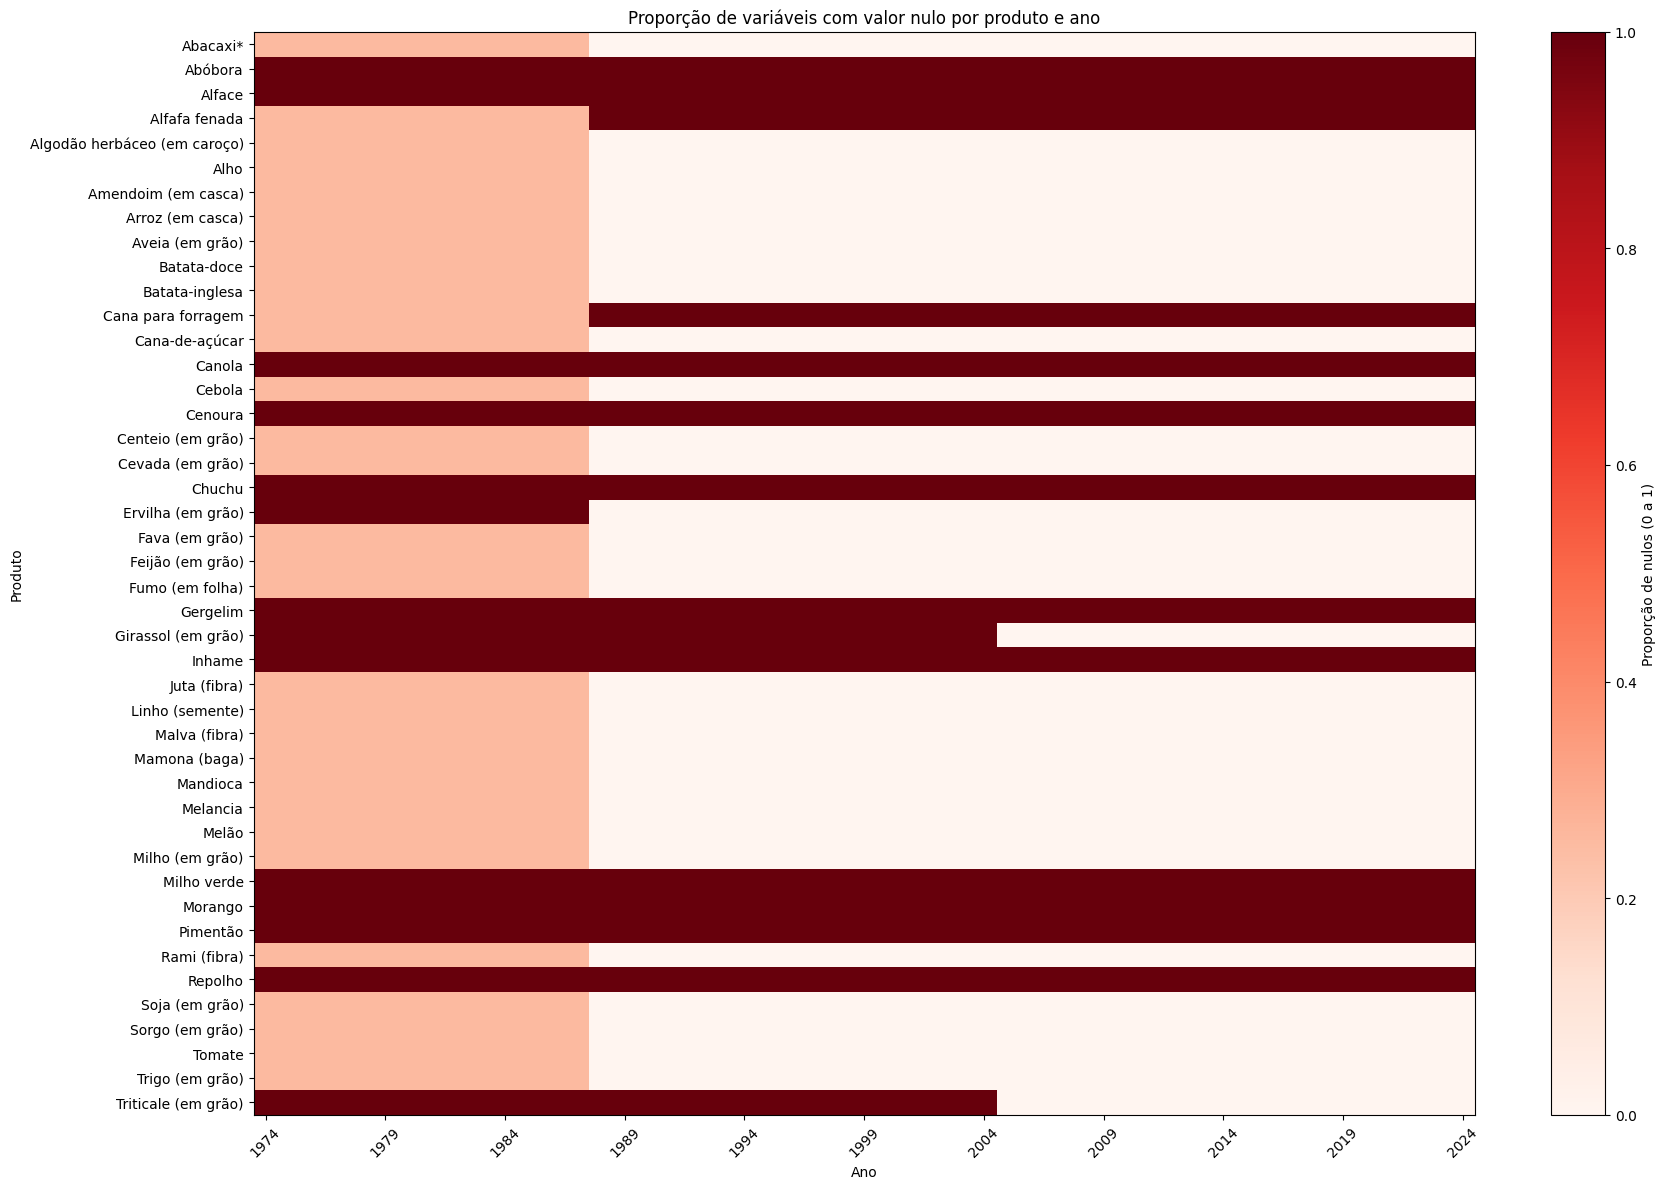

In [31]:
# True indica que o valor daquela linha está ausente (NaN).
df_agro["nulo"] = df_agro["valor"].isna()

# A média de True/False corresponde à proporção de nulos.
proporcao_nulos = df_agro.groupby(["ano", "variavel"])["nulo"].mean().unstack()
print("Proporção de valores nulos por ano e variável:")
display(proporcao_nulos)

# Conta quantas variáveis (de até quatro) estão nulas em cada produto-ano.
nulos_por_produto_ano = df_agro.groupby(["produto", "ano"])["nulo"].sum()
print("Combinações produto-ano, por número de variáveis nulas:")
display(nulos_por_produto_ano.value_counts().sort_index())

# Cada célula do mapa mostra a proporção de variáveis nulas naquele produto-ano.
mapa_nulos = df_agro.pivot_table(
    index="produto", columns="ano", values="nulo", aggfunc="mean"
)
fig, ax = plt.subplots(figsize=(18, 12))
imagem = ax.imshow(
    mapa_nulos, aspect="auto", interpolation="nearest",
    cmap="Reds", vmin=0, vmax=1
)
anos = mapa_nulos.columns
posicoes_anos = np.arange(len(anos))[::5]
ax.set_xticks(posicoes_anos)
ax.set_xticklabels([ano.strftime("%Y") for ano in anos[::5]], rotation=45)
ax.set_yticks(np.arange(len(mapa_nulos.index)))
ax.set_yticklabels(mapa_nulos.index)
ax.set_xlabel("Ano")
ax.set_ylabel("Produto")
ax.set_title("Proporção de variáveis com valor nulo por produto e ano")
fig.colorbar(imagem, ax=ax, label="Proporção de nulos (0 a 1)")
plt.tight_layout()
plt.show()

historico_alteracoes.append("Foi analisado o padrão dos valores nulos por ano, variável e produto.")


### Conclusão sobre os nulos

Os nulos apresentam padrão por ano, variável e produto: há anos e produtos com ausências concentradas, e algumas combinações produto-ano têm as quatro variáveis nulas enquanto outras não têm nenhuma. Portanto, os nulos não são aleatórios e não vou imputar valores.

## Etapa 6 — Nulos nas séries de soja e mandioca

A tabela abaixo conta os nulos de `valor` para cada variável de soja e mandioca. Para a análise proposta, `Quantidade produzida` e `Área colhida` têm 51 observações e nenhum nulo em cada produto, então essas séries estão completas; `Área plantada` tem 14 nulos em cada produto.

In [32]:
# Mantém somente os dois produtos da pergunta.
produtos_alvo = ["Soja (em grão)", "Mandioca"]
df_soja_mandioca = df_agro.loc[df_agro["produto"].isin(produtos_alvo)]

# Conta os valores ausentes por produto e variável.
nulos_por_produto_variavel = (
    df_soja_mandioca.groupby(["produto", "variavel"])["valor"]
    .apply(lambda valores: valores.isna().sum())
    .unstack(fill_value=0)
)
display(nulos_por_produto_variavel)

variavel,Quantidade produzida,Valor da produção,Área colhida,Área plantada
produto,,,,
Mandioca,0,0,0,14
Soja (em grão),0,0,0,14


## Etapa A — Verificar duplicatas

O código conta linhas totalmente duplicadas e combinações repetidas de ano, produto e variável, mostrando as linhas correspondentes quando existem. Só remove registros totalmente idênticos; combinações repetidas com outros valores são mantidas para investigação.

In [33]:
# Conta linhas iguais em todas as colunas.
total_duplicatas_identicas = df_agro.duplicated().sum()

# Verifica combinações repetidas de ano, produto e variável.
chaves = ["ano", "produto", "variavel"]
mascara_chaves_repetidas = df_agro.duplicated(subset=chaves, keep=False)
total_linhas_com_chave_repetida = df_agro.duplicated(subset=chaves).sum()
total_combinacoes_repetidas = (
    df_agro.loc[mascara_chaves_repetidas, chaves].drop_duplicates().shape[0]
)

print("Linhas totalmente duplicadas:", total_duplicatas_identicas)
print("Linhas que repetem uma combinação ano-produto-variável:", total_linhas_com_chave_repetida)
print("Combinações ano-produto-variável repetidas:", total_combinacoes_repetidas)

# Se existirem duplicatas idênticas, mostra as linhas antes de removê-las.
if total_duplicatas_identicas > 0:
    print("Linhas totalmente duplicadas:")
    display(df_agro.loc[df_agro.duplicated(keep=False)].sort_values(chaves))
    df_agro = df_agro.drop_duplicates().copy()
    print("Duplicatas idênticas removidas:", total_duplicatas_identicas)
else:
    print("Não há linhas totalmente duplicadas para remover.")

# Mostra todas as linhas das chaves repetidas, inclusive quando os dados diferem.
if total_linhas_com_chave_repetida > 0:
    print("Linhas com combinação ano-produto-variável repetida:")
    display(df_agro.loc[mascara_chaves_repetidas].sort_values(chaves))
else:
    print("Não há combinações ano-produto-variável repetidas.")

historico_alteracoes.append("Foram verificadas as duplicatas de linhas e combinações ano-produto-variável.")


Linhas totalmente duplicadas: 0
Linhas que repetem uma combinação ano-produto-variável: 0
Combinações ano-produto-variável repetidas: 0
Não há linhas totalmente duplicadas para remover.
Não há combinações ano-produto-variável repetidas.


## Etapa B — Investigar variações grandes

Para cada variável, o gráfico mostra as séries anuais de soja e mandioca e destaca variações maiores que 100% ou menores que -50%. A tabela lista os anos sinalizados; os valores originais não são corrigidos nem removidos.

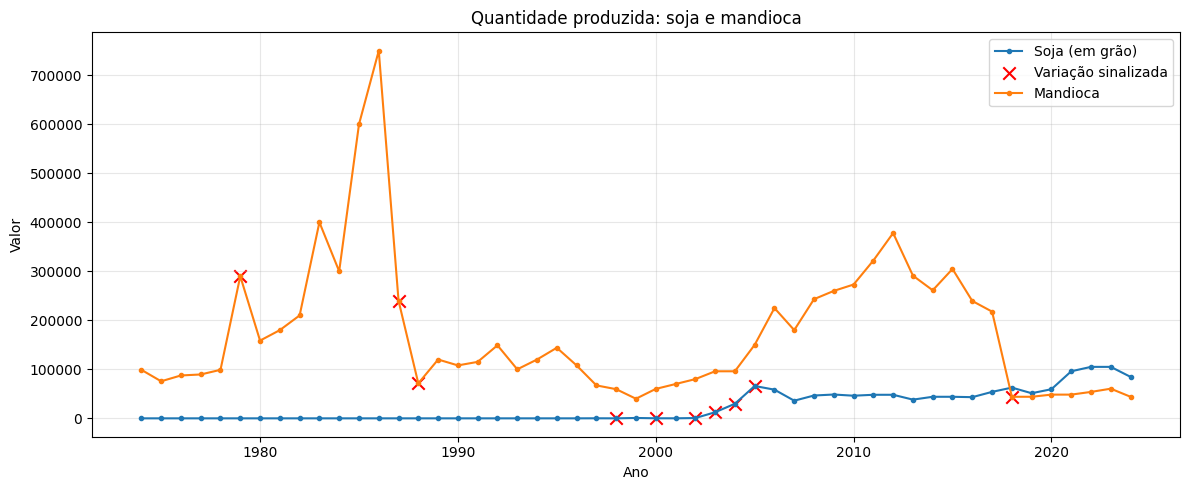

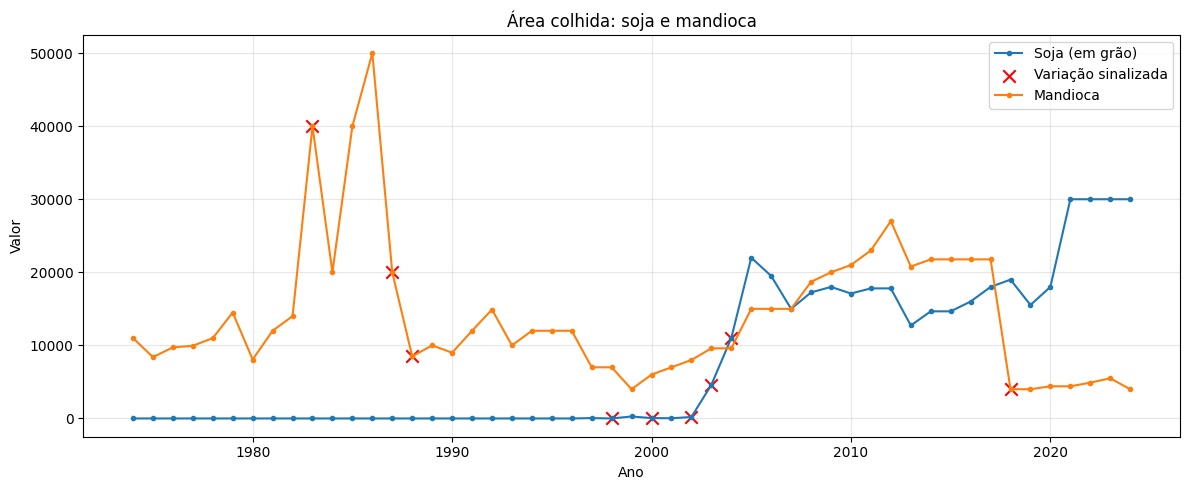

,produto,variavel,ano,valor,variacao_percentual
6,Mandioca,Quantidade produzida,1979,290000.0,192.929293
7,Mandioca,Quantidade produzida,1987,240000.0,-68.000000
8,Mandioca,Quantidade produzida,1988,71400.0,-70.250000
9,Mandioca,Quantidade produzida,2018,44000.0,-79.788700
0,Soja (em grão),Quantidade produzida,1998,0.0,-100.000000
1,Soja (em grão),Quantidade produzida,2000,135.0,-82.260184
2,Soja (em grão),Quantidade produzida,2002,600.0,700.000000
3,Soja (em grão),Quantidade produzida,2003,12420.0,1970.000000
4,Soja (em grão),Quantidade produzida,2004,29700.0,139.130435
5,Soja (em grão),Quantidade produzida,2005,66000.0,122.222222


In [34]:
# Seleciona as duas culturas e as duas variáveis da análise.
culturas = ["Soja (em grão)", "Mandioca"]
variaveis_analise = ["Quantidade produzida", "Área colhida"]
dados_variacoes = df_agro.loc[
    df_agro["produto"].isin(culturas)
    & df_agro["variavel"].isin(variaveis_analise)
].copy()

variacoes_sinalizadas = []

# Cria um gráfico para cada variável, com as duas culturas.
for variavel_atual in variaveis_analise:
    fig, ax = plt.subplots(figsize=(12, 5))
    rotulo_destaque_usado = False

    for cultura in culturas:
        serie = dados_variacoes.loc[
            (dados_variacoes["produto"] == cultura)
            & (dados_variacoes["variavel"] == variavel_atual),
            ["ano", "valor"],
        ].sort_values("ano").copy()

        # Compara cada ano com o ano anterior da mesma cultura.
        serie["variacao_percentual"] = serie["valor"].pct_change(fill_method=None) * 100
        variacao_finita = np.isfinite(serie["variacao_percentual"])
        destaque = variacao_finita & (
            (serie["variacao_percentual"] > 100)
            | (serie["variacao_percentual"] < -50)
        )

        ax.plot(serie["ano"], serie["valor"], marker="o", markersize=3, label=cultura)

        # Marca no gráfico os pontos que ultrapassam os limites definidos.
        if destaque.any():
            rotulo = "Variação sinalizada" if not rotulo_destaque_usado else None
            ax.scatter(
                serie.loc[destaque, "ano"], serie.loc[destaque, "valor"],
                color="red", marker="x", s=80, label=rotulo,
            )
            rotulo_destaque_usado = True

            for _, linha in serie.loc[destaque].iterrows():
                variacoes_sinalizadas.append({
                    "produto": cultura,
                    "variavel": variavel_atual,
                    "ano": linha["ano"],
                    "valor": linha["valor"],
                    "variacao_percentual": linha["variacao_percentual"],
                })

    ax.set_title(f"{variavel_atual}: soja e mandioca")
    ax.set_xlabel("Ano")
    ax.set_ylabel("Valor")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Lista os anos com variações grandes; mudanças a partir de zero não têm percentual finito.
colunas_variacoes = ["produto", "variavel", "ano", "valor", "variacao_percentual"]
tabela_variacoes_sinalizadas = pd.DataFrame(
    variacoes_sinalizadas, columns=colunas_variacoes
)
if tabela_variacoes_sinalizadas.empty:
    print("Nenhum ano ultrapassou os limites de variação definidos.")
else:
    tabela_variacoes_sinalizadas["ano"] = (
        tabela_variacoes_sinalizadas["ano"].dt.year
    )
    display(tabela_variacoes_sinalizadas.sort_values(["variavel", "produto", "ano"]))

historico_alteracoes.append("Foram investigadas as variações grandes da etapa B; os valores sinalizados foram mantidos.")


## Etapa B2 — Ajuste dos gráficos

Os dois gráficos mantêm as séries anuais de `Quantidade produzida` e `Área colhida` para soja e mandioca. O X destaca somente a soja em 2003 e a mandioca em 2018; títulos, legendas e demais pontos continuam iguais.

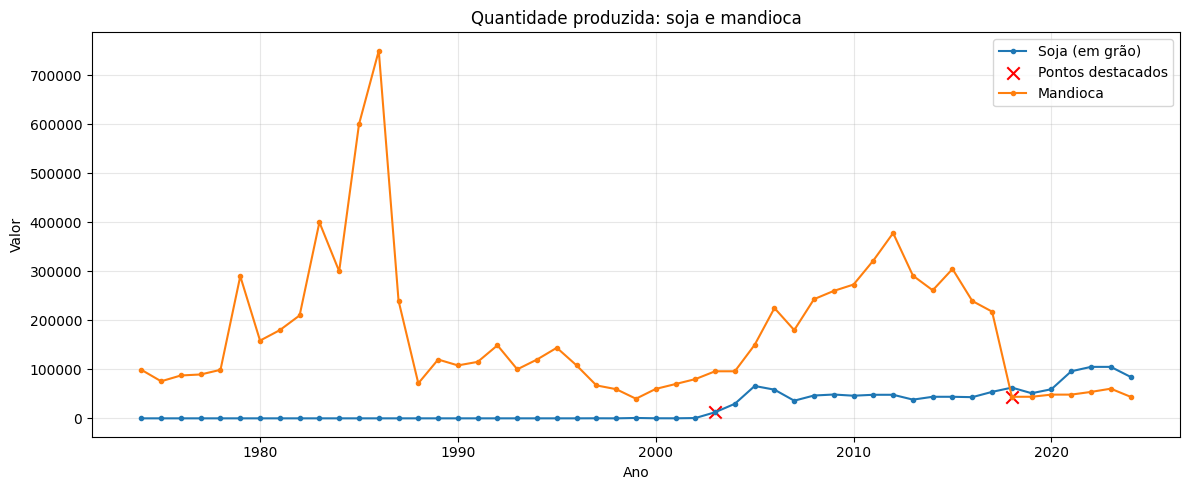

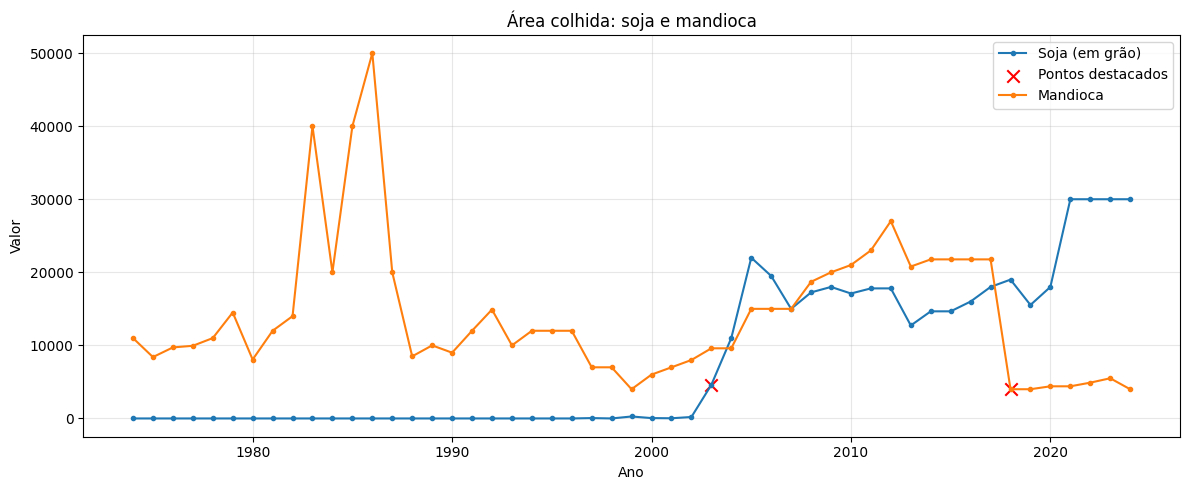

In [35]:
# Seleciona soja e mandioca nas duas variáveis que serão comparadas.
culturas = ["Soja (em grão)", "Mandioca"]
variaveis_analise = ["Quantidade produzida", "Área colhida"]
dados_graficos = df_agro.loc[
    df_agro["produto"].isin(culturas)
    & df_agro["variavel"].isin(variaveis_analise)
].copy()

# Define os dois pontos que devem receber o X.
anos_destaque = {
    "Soja (em grão)": pd.Timestamp("2003-01-01"),
    "Mandioca": pd.Timestamp("2018-01-01"),
}

# Faz um gráfico para cada variável, mantendo as duas culturas juntas.
for variavel_atual in variaveis_analise:
    fig, ax = plt.subplots(figsize=(12, 5))
    rotulo_destaque_usado = False

    for cultura in culturas:
        serie = dados_graficos.loc[
            (dados_graficos["produto"] == cultura)
            & (dados_graficos["variavel"] == variavel_atual),
            ["ano", "valor"],
        ].sort_values("ano")

        ax.plot(serie["ano"], serie["valor"], marker="o", markersize=3, label=cultura)

        # Destaca apenas o ano definido para esta cultura.
        ponto = serie.loc[serie["ano"].eq(anos_destaque[cultura])]
        if not ponto.empty:
            rotulo = "Pontos destacados" if not rotulo_destaque_usado else None
            ax.scatter(
                ponto["ano"], ponto["valor"],
                color="red", marker="x", s=80, label=rotulo,
            )
            rotulo_destaque_usado = True

    ax.set_title(f"{variavel_atual}: soja e mandioca")
    ax.set_xlabel("Ano")
    ax.set_ylabel("Valor")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

historico_alteracoes.append("Os gráficos da etapa B2 foram ajustados para destacar apenas os dois pontos solicitados.")


## Etapa B3 — Rendimento por ano

O código divide a quantidade produzida pela área colhida para calcular o rendimento em toneladas por hectare. Área zero não será dividida, e os valores ausentes continuarão ausentes; a tabela e o gráfico servem apenas para observar a série.

Rendimento anual em toneladas por hectare:


,ano,produto,Rendimento (t/ha)
0,1974-01-01,Mandioca,9.000000
2,1975-01-01,Mandioca,9.000000
4,1976-01-01,Mandioca,9.000000
6,1977-01-01,Mandioca,8.999698
8,1978-01-01,Mandioca,9.000000
...,...,...,...
93,2020-01-01,Soja (em grão),3.300000
95,2021-01-01,Soja (em grão),3.200000
97,2022-01-01,Soja (em grão),3.500000
99,2023-01-01,Soja (em grão),3.500000


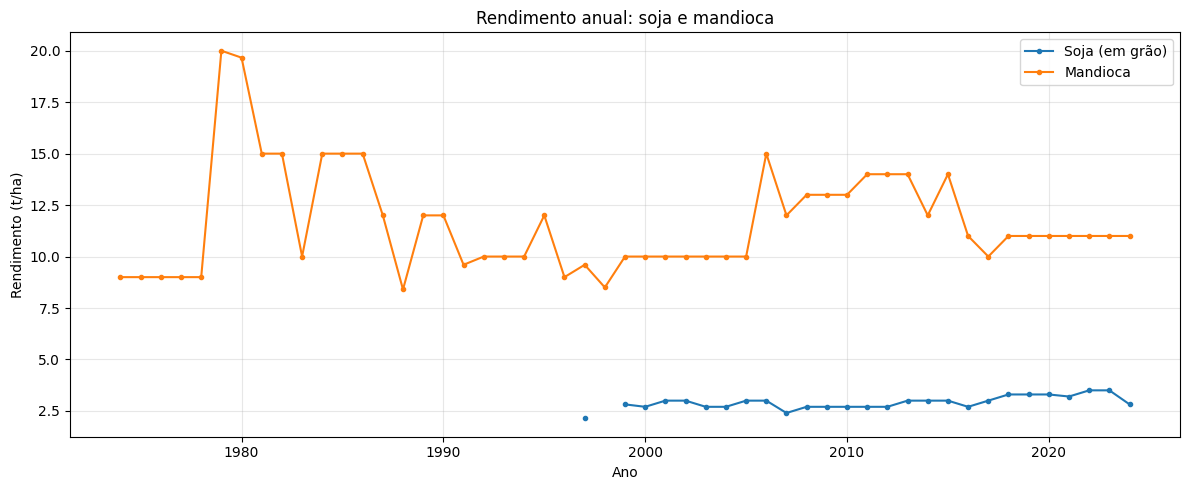

In [36]:
# Organiza quantidade produzida e área colhida em colunas para cada ano e produto.
rendimento_base = df_agro.loc[
    df_agro["produto"].isin(culturas)
    & df_agro["variavel"].isin(["Quantidade produzida", "Área colhida"]),
    ["ano", "produto", "variavel", "valor"],
].pivot(index=["ano", "produto"], columns="variavel", values="valor")

# Área zero vira NaN somente no cálculo, para evitar divisão por zero.
area_para_dividir = rendimento_base["Área colhida"].where(
    rendimento_base["Área colhida"] != 0
)
rendimento = rendimento_base["Quantidade produzida"].div(area_para_dividir)
rendimentos_por_ano = (
    rendimento.rename("Rendimento (t/ha)")
    .reset_index()
    .sort_values(["produto", "ano"])
)

print("Rendimento anual em toneladas por hectare:")
display(rendimentos_por_ano)

# Desenha uma linha para cada produto, sem alterar os valores originais.
fig, ax = plt.subplots(figsize=(12, 5))
for cultura in culturas:
    serie = rendimentos_por_ano.loc[rendimentos_por_ano["produto"] == cultura]
    ax.plot(serie["ano"], serie["Rendimento (t/ha)"], marker="o", markersize=3, label=cultura)

ax.set_title("Rendimento anual: soja e mandioca")
ax.set_xlabel("Ano")
ax.set_ylabel("Rendimento (t/ha)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

historico_alteracoes.append("Foi calculado o rendimento anual (quantidade produzida / área colhida) para soja e mandioca, sem corrigir valores.")


## Etapa C — Conferir a lógica das áreas

O código organiza as áreas plantada e colhida por produto e ano, ignora pares em que alguma área é nula e conta os casos em que a área colhida supera a plantada. Ele mostra os 10 primeiros casos para conferência, sem alterar os dados.

In [37]:
# Organiza cada área em uma coluna para comparar os valores do mesmo produto e ano.
areas = df_agro.loc[
    df_agro["variavel"].isin(["Área plantada", "Área colhida"]),
    ["produto", "ano", "variavel", "valor"],
].pivot(index=["produto", "ano"], columns="variavel", values="valor")

# Remove apenas da comparação os pares em que falta uma das duas áreas.
areas_completas = areas.dropna(subset=["Área plantada", "Área colhida"])
area_colhida_maior = areas_completas.loc[
    areas_completas["Área colhida"] > areas_completas["Área plantada"]
].reset_index()

print("Casos em que Área colhida > Área plantada:", len(area_colhida_maior))
print("Primeiros 10 casos:")
display(area_colhida_maior.head(10))

historico_alteracoes.append("Foi conferido, por produto e ano, se a área colhida supera a área plantada; os casos foram apenas listados.")


Casos em que Área colhida > Área plantada: 0
Primeiros 10 casos:


variavel,produto,ano,Área colhida,Área plantada


## Etapa D — Resumo das decisões de tratamento

- **Tipos convertidos:** `ano` para datetime e `valor` para float.
- **Símbolos da base:** `-` foi tratado como zero e `...` como NaN.
- **Ano:** 2025 foi removido por estar fora do período da pergunta (1974–2024).
- **Unidade:** a unidade de `Área plantada` foi preenchida com `Hectares`; os nulos de unidade eram todos dessa variável, de 1974 a 1987.
- **Nulos de valor:** não foram imputados, porque a ausência não é aleatória e segue padrão por ano, variável e produto.
- **Valor da produção:** não será usado, porque a moeda mudou ao longo dos anos (Cruzeiro, Cruzado e Real) e os valores não são comparáveis. A análise usará `Quantidade produzida` e `Área colhida`.
- **Valores sinalizados na etapa B:** foram mantidos. As variações extremas da soja ocorrem sobre bases muito pequenas (1997 a 2002) e, a partir de 2003, correspondem à expansão real da cultura. As oscilações da mandioca nos anos 80 e a queda de 2018 mostram área e quantidade variando juntas, com rendimento plausível.
- **Limitação:** alguns valores recentes são repetidos ou arredondados (área colhida de soja em 30.000 ha de 2021 a 2024; rendimento da mandioca quase sempre 10 ou 11 t/ha desde 1988), o que sugere estimativas do IBGE.
- **Resultado da etapa C:** nenhum caso em que a área colhida supera a área plantada (0 casos entre os pares com as duas áreas disponíveis), então não há inconsistência de lógica entre essas variáveis.

# Histórico de alterações

In [38]:
exibir_historico()


                        HISTÓRICO DE ALTERAÇÕES                         
01. A coluna valor foi convertida para float; '-' virou zero e '...' virou NaN.
02. As colunas produto, variavel e unidade foram verificadas e tiveram espaços extras removidos.
03. Foram removidos 176 registros de 2025 e a coluna ano foi convertida para datetime.
04. Os valores nulos foram contabilizados por coluna; nenhum dado foi removido ou imputado nessa etapa.
05. A unidade dos registros de Área plantada sem unidade foi preenchida com Hectares.
06. Foi analisado o padrão dos valores nulos por ano, variável e produto.
07. Foram verificadas as duplicatas de linhas e combinações ano-produto-variável.
08. Foram investigadas as variações grandes da etapa B; os valores sinalizados foram mantidos.
09. Os gráficos da etapa B2 foram ajustados para destacar apenas os dois pontos solicitados.
10. Foi calculado o rendimento anual (quantidade produzida / área colhida) para soja e mandioca, sem corrigir valores.
11. Foi c